In [1]:

from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()

if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "scripts"))

In [2]:
from geography import (
    AREA_CRS,
    getGeographicCrosswalk,
    validateCrosswalk,
)

DATA = ROOT / "data" / "processed"

YEARS = (2018, 2022)

candidates = {
    year: pd.read_csv(
        DATA / f"essendon_{year}_candidates.csv"
    )
    for year in YEARS
}

votes = {
    year: pd.read_csv(
        DATA / f"essendon_{year}_votes.csv"
    )
    for year in YEARS
}

locations = {
    year: pd.read_csv(
        DATA / f"essendon_{year}_locations.csv"
    )
    for year in YEARS
}

demographics = pd.read_csv(
    DATA / "vic_2021_suburb_demographics.csv",
    dtype={"SAL_CODE_2021": str},
    low_memory=False,
)

crosswalk = pd.read_csv(
    DATA / "essendonSalCrosswalk.csv",
    dtype={"SAL_CODE_2021": str},
)

print("Historical elections:", YEARS)
print("2021 Census SAL records:", len(demographics))
print("SALs intersecting Essendon:", len(crosswalk))

Historical elections: (2018, 2022)
2021 Census SAL records: 2946
SALs intersecting Essendon: 10


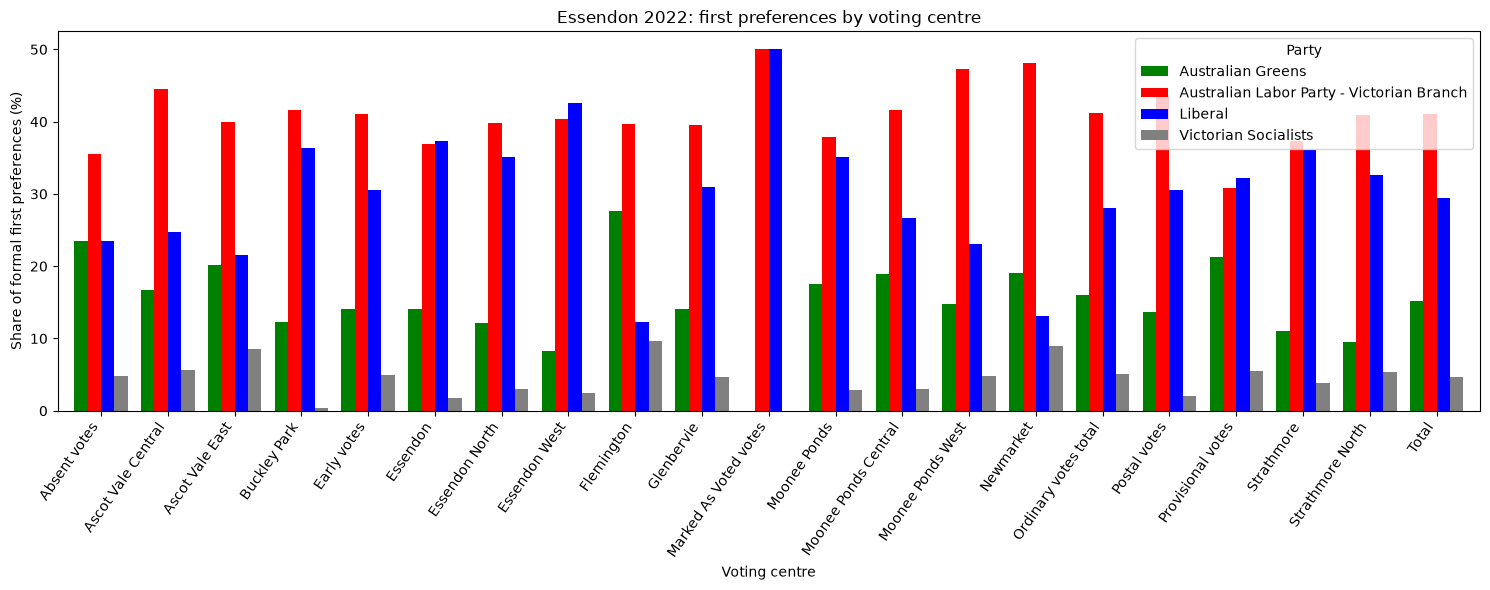

In [7]:
YEAR = 2022
partyTotals = (
    pd.to_numeric(votes[YEAR]["votes"], errors="coerce")
    .fillna(0)
    .groupby(votes[YEAR]["party"])
    .sum()
    .nlargest(4)
)

partyColours = {
    "Australian Greens": "green",
    "Australian Labor Party - Victorian Branch": "red",
    "Liberal": "blue",
}
centre_names = set(locations[YEAR]["location"].dropna())

ordinary = votes[YEAR][
    votes[YEAR]["location"].isin(centre_names)
].copy()

ordinary["votes"] = pd.to_numeric(ordinary["votes"], errors="coerce").fillna(0)

centreParties = (
    ordinary.groupby(["location", "party"], as_index=False)["votes"]
    .sum()
)

centreTotals = centreParties.groupby("location")["votes"].transform("sum")

centreParties["share"] = (
    100 * centreParties["votes"] / centreTotals
)

largestParties = (
    centreParties.groupby("party")["votes"]
    .sum()
    .nlargest(4)
    .index
)

plotData = (
    centreParties[centreParties["party"].isin(largestParties)]
    .pivot(index="location", columns="party", values="share")
    .fillna(0)
)

colours = [partyColours.get(party, "grey") for party in plotData.columns]

ax = plotData.plot.bar(
    figsize=(15, 6),
    width=0.8,
    color=colours,
)

ax.set_title(f"Essendon {YEAR}: first preferences by voting centre")
ax.set_xlabel("Voting centre")
ax.set_ylabel("Share of formal first preferences (%)")

plt.xticks(rotation=55, ha="right")
plt.legend(title="Party")
plt.tight_layout()
plt.show()

In [8]:

centreVariation = (
    centreParties.groupby("party")["share"]
    .agg(["min", "max", "mean", "std"])
    .sort_values("std", ascending=False)
)

display(centreVariation.round(2))

,min,max,mean,std
party,,,,
Liberal,12.26,50.00,30.10,8.82
Australian Greens,0.00,27.70,15.24,5.82
Australian Labor Party - Victorian Branch,30.82,50.00,40.90,4.30
Victorian Socialists,0.00,9.70,4.40,2.55
Freedom Party of Victoria,0.00,5.67,2.27,1.25
Fiona Patten's Reason Party,0.00,4.50,2.32,1.18
Animal Justice Party,0.00,5.48,2.79,1.04
Family First Victoria,0.00,3.73,2.00,0.80


In [12]:
def centrePartyShares(year):
    ordinary = votes[year].loc[
        votes[year]["rowType"].eq("votingCentre")
    ].copy()

    ordinary["votes"] = pd.to_numeric(
        ordinary["votes"], errors="coerce"
    ).fillna(0)

    frame = (
        ordinary.groupby(["location", "party"], as_index=False)["votes"]
        .sum()
    )

    totals = frame.groupby("location")["votes"].transform("sum")
    frame["share"] = 100 * frame["votes"] / totals

    return frame


a = centrePartyShares(2018)
b = centrePartyShares(2022)

partyAliases = {
    "AUSTRALIAN GREENS": "Australian Greens",
    "AUSTRALIAN LABOR PARTY": (
        "Australian Labor Party - Victorian Branch"
    ),
    "LIBERAL": "Liberal",
}

a["party"] = a["party"].replace(partyAliases)

comparison = a.merge(
    b,
    on=["location", "party"],
    how="inner",
    suffixes=("_2018", "_2022"),
    validate="one_to_one",
)

comparison["change_pp"] = (
    comparison["share_2022"] - comparison["share_2018"]
)

display(
    comparison[
        ["location", "party", "share_2018", "share_2022", "change_pp"]
    ].sort_values("change_pp").round(2)
)

print("Matched centre-party observations:", len(comparison))

,location,party,share_2018,share_2022,change_pp
19,Flemington,Australian Labor Party - Victorian Branch,53.94,39.64,-14.30
40,Strathmore North,Australian Labor Party - Victorian Branch,52.66,40.87,-11.79
34,Newmarket,Australian Labor Party - Victorian Branch,59.83,48.08,-11.75
37,Strathmore,Australian Labor Party - Victorian Branch,48.64,37.38,-11.25
31,Moonee Ponds West,Australian Labor Party - Victorian Branch,56.03,47.23,-8.80
22,Glenbervie,Australian Labor Party - Victorian Branch,47.59,39.58,-8.00
4,Ascot Vale East,Australian Labor Party - Victorian Branch,47.64,40.02,-7.62
28,Moonee Ponds Central,Australian Labor Party - Victorian Branch,49.19,41.68,-7.52
3,Ascot Vale East,Australian Greens,25.73,20.17,-5.57
13,Essendon North,Australian Labor Party - Victorian Branch,45.02,39.88,-5.14


Matched centre-party observations: 42


districtAreaKm2           24.484166
salIntersectionAreaKm2    24.484166
districtCoverage           1.000000
intersectingSuburbs       10.000000
Name: Value, dtype: float64

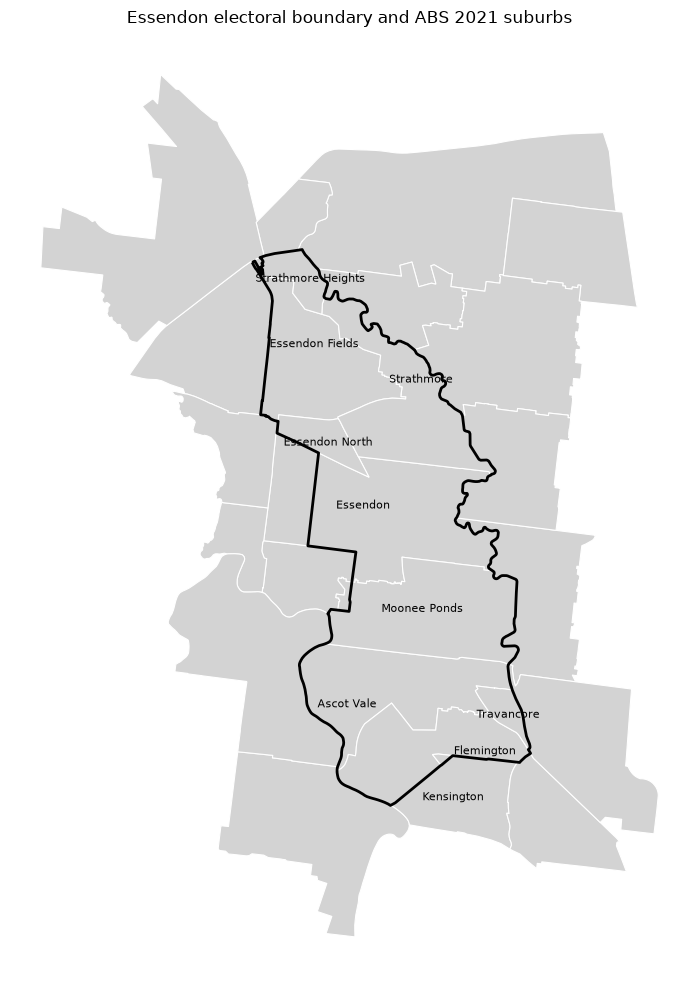

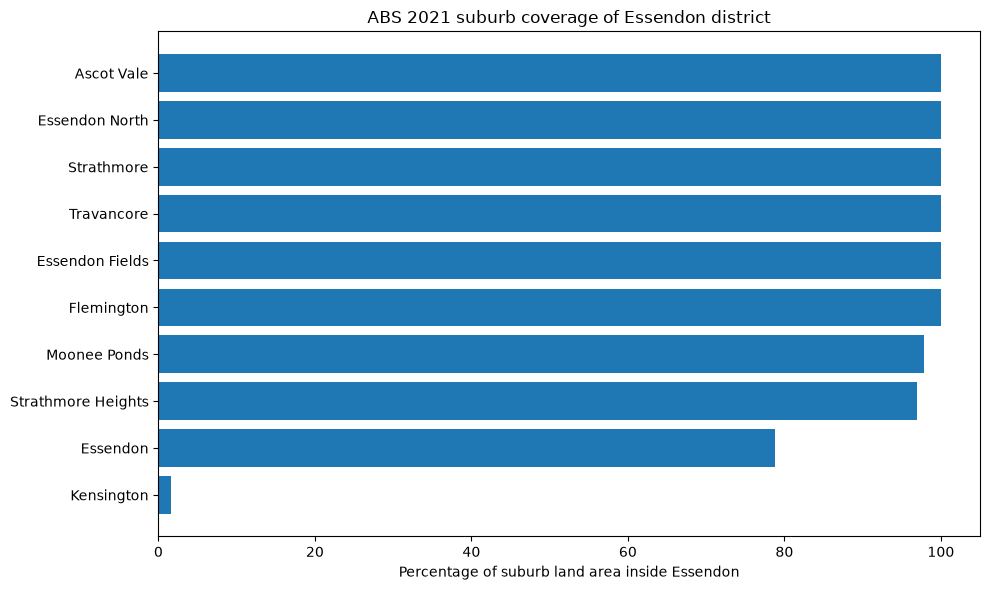

,suburb,suburbAreaKm2,areaInEssendonKm2,suburbCoverage,districtAreaShare
0,Essendon,6.1592,4.8511,0.7876,0.1981
1,Moonee Ponds,4.3555,4.2620,0.9785,0.1741
2,Ascot Vale,3.8386,3.8386,1.0000,0.1568
3,Strathmore,3.4536,3.4536,1.0000,0.1411
4,Essendon Fields,3.3551,3.3551,1.0000,0.1370
5,Flemington,2.8695,2.8695,1.0000,0.1172
6,Essendon North,0.7324,0.7324,1.0000,0.0299
7,Strathmore Heights,0.6913,0.6705,0.9700,0.0274
8,Travancore,0.4183,0.4183,1.0000,0.0171
9,Kensington,2.1372,0.0331,0.0155,0.0014


In [16]:
# geographic harmonisation

crosswalk, suburbs, district = getGeographicCrosswalk()

report = validateCrosswalk(crosswalk, district)

display(pd.Series(report, name="Value"))

fig, ax = plt.subplots(figsize=(10, 10))

suburbs.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="white",
    linewidth=0.8,
)

district.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2,
)

# Label suburbs whose polygons intersect Essendon.
intersecting = suburbs[
    suburbs["SAL_CODE_2021"].isin(
        crosswalk["SAL_CODE_2021"]
    )
]

for row in intersecting.itertuples():
    point = row.geometry.representative_point()

    ax.annotate(
        row.suburb,
        (point.x, point.y),
        fontsize=8,
        ha="center",
    )

ax.set_title(
    "Essendon electoral boundary and ABS 2021 suburbs"
)
ax.set_axis_off()

plt.tight_layout()
plt.show()


coverage = crosswalk.sort_values(
    "suburbCoverage",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    coverage["suburb"],
    100 * coverage["suburbCoverage"],
)

ax.set_xlabel(
    "Percentage of suburb land area inside Essendon"
)
ax.set_title(
    "ABS 2021 suburb coverage of Essendon district"
)

plt.tight_layout()
plt.show()

display(
    crosswalk[
        [
            "suburb",
            "suburbAreaKm2",
            "areaInEssendonKm2",
            "suburbCoverage",
            "districtAreaShare",
        ]
    ].round(4)
)

In [17]:

localDemographics = crosswalk.merge(
    demographics,
    on="SAL_CODE_2021",
    how="left",
    validate="one_to_one",
    suffixes=("_boundary", "_census"),
)

if len(localDemographics) != len(crosswalk):
    raise ValueError("Census join changed the row count")

display(localDemographics.head())

print(
    "Matched suburb geometries:",
    len(localDemographics),
)

print(
    "Available Census columns:",
    len(localDemographics.columns),
)

,SAL_CODE_2021,suburb_boundary,suburbAreaKm2,areaInEssendonKm2,suburbCoverage,districtAreaShare,suburb_census,Tot_P_M,Tot_P_F,Tot_P_P,...,High_yr_schl_comp_Yr_8_belw_P,High_yr_schl_comp_D_n_g_sch_M,High_yr_schl_comp_D_n_g_sch_F,High_yr_schl_comp_D_n_g_sch_P,Count_psns_occ_priv_dwgs_M,Count_psns_occ_priv_dwgs_F,Count_psns_occ_priv_dwgs_P,Count_Persons_other_dwgs_M,Count_Persons_other_dwgs_F,Count_Persons_other_dwgs_P
0,20885,Essendon,6.159244,4.851110,0.787615,0.198133,Essendon,10299,10941,21240,...,612,50,77,123,9784,10347,20130,429,436,863
1,21742,Moonee Ponds,4.355549,4.261975,0.978516,0.174071,Moonee Ponds,7821,8401,16224,...,598,47,87,130,7354,7922,15276,357,343,705
2,20075,Ascot Vale,3.838566,3.838566,1.000000,0.156777,Ascot Vale,7469,7727,15197,...,498,66,118,188,6951,7238,14188,396,373,770
3,22380,Strathmore,3.453617,3.453617,1.000000,0.141055,Strathmore,4483,4497,8980,...,248,14,28,40,4322,4364,8686,88,79,167
4,20886,Essendon Fields,3.355067,3.355067,1.000000,0.137030,Essendon Fields,5,6,13,...,0,0,0,0,0,0,0,73,13,83


Matched suburb geometries: 10
Available Census columns: 115
